# DS 6021 Lab 7: Parts 2 and 3 - Multinomial Logistic Regression and KNN

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, cross_val_predict
from sklearn.metrics import log_loss, accuracy_score, precision_score, recall_score, ConfusionMatrixDisplay

warnings.filterwarnings("ignore")   # This suppresses some of the warning output in the saga solver

col_names = ["RI", "Na", "Mg", "Al", "Si", "K", "Ca", "Ba", "Fe", "type"]
glass = pd.read_csv("glass.csv", header=None, names=col_names)

class_names = {1: "building_float", 2: "building_nonfloat", 3: "vehicle_float",
               5: "containers", 6: "tableware", 7: "headlamps"}
features = ["RI", "Na", "Mg", "Al", "Si", "K", "Ca", "Ba", "Fe"]

X = glass[features]
y = glass["type"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=113
)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=224)

### Helper functions

`cv_scores`: mean and SD of log loss and accuracy across the 5 folds. `cv_pred`: out-of-fold predicted class for every training fragment.

In [2]:
def cv_scores(model):
    res = cross_validate(model, X_train, y_train, cv=cv, scoring=["neg_log_loss", "accuracy"])
    return {
        "log loss (mean)": -res["test_neg_log_loss"].mean(),
        "log loss (sd)": res["test_neg_log_loss"].std(),
        "accuracy (mean)": res["test_accuracy"].mean(),
        "accuracy (sd)": res["test_accuracy"].std(),
    }

def cv_pred(model):
    return cross_val_predict(model, X_train, y_train, cv=cv)

# Part 2: Multinomial Logistic Regression

### Question 1

##### Part a

In [3]:
X_train.describe().T[["mean", "std", "min", "max"]].round(3)

,mean,std,min,max
RI,1.518,0.003,1.511,1.534
Na,13.398,0.833,10.730,17.380
Mg,2.679,1.458,0.000,4.490
Al,1.423,0.493,0.290,3.500
Si,72.659,0.790,69.810,75.410
K,0.475,0.568,0.000,6.210
Ca,9.006,1.530,5.430,16.190
Ba,0.185,0.523,0.000,3.150
Fe,0.059,0.097,0.000,0.510


##### Part b

In [4]:
split_counts = pd.DataFrame({
    "training set": y_train.value_counts().sort_index(),
    "test set": y_test.value_counts().sort_index(),
})
split_counts.index = [class_names[c] for c in split_counts.index]
split_counts

,training set,test set
building_float,56,14
building_nonfloat,61,15
vehicle_float,14,3
containers,10,3
tableware,7,2
headlamps,23,6


- Tableware is the rarest class with vehicle_float and containers being rare but slightly more common than tableware. Building_nonfloat is the most common class with building_float just behind it.


##### Part c

In [5]:
most_common = y_train.mode()[0]
print(f"Most common class: {class_names[most_common]}")
print(f"Accuracy on the training set: {(y_train == most_common).mean():.4f}")

Most common class: building_nonfloat
Accuracy on the training set: 0.3567


##### Part d

In [6]:
class_props = y_train.value_counts(normalize=True).sort_index().values
ll_base = log_loss(y_train, np.tile(class_props, (len(y_train), 1)))
print(f"Base-rate log loss: {ll_base:.4f}")

Base-rate log loss: 1.5049


##### Part e

- That is because the model is not predicting every class with 1/K but is predicting some classes to be more common than others, giving it a lower log loss than the base case of 1/K for every class.


### Question 2

##### Part a

In [7]:
oxides = ["Na", "Mg", "Al", "Si", "K", "Ca", "Ba", "Fe"]
oxide_sum = glass[oxides].sum(axis=1)
oxide_sum.describe().round(4)

count    214.0000
mean      99.8743
std        0.1221
min       99.0200
25%       99.8100
50%       99.8900
75%       99.9600
max      100.1000
dtype: float64

- The sums are all very close to 100% meaning each sample is made up almost entirely of the eight oxides


##### Part b

In [8]:
model_unpen = Pipeline(steps=[
    ("scale", StandardScaler()),
    ("model", LogisticRegression(C=np.inf, max_iter=50000)),
])

unpen_scores = cv_scores(model_unpen)
print(f"Mean CV log loss: {unpen_scores['log loss (mean)']:.4f}")
print(f"Mean CV accuracy: {unpen_scores['accuracy (mean)']:.4f}")

model_unpen.fit(X_train, y_train)
pd.DataFrame(
    model_unpen.named_steps["model"].coef_.T,
    index=features,
    columns=[class_names[c] for c in model_unpen.named_steps["model"].classes_],
).round(3)

Mean CV log loss: 4.1417
Mean CV accuracy: 0.6262


,building_float,building_nonfloat,vehicle_float,containers,tableware,headlamps
RI,-13.539,-12.277,-19.088,-12.707,24.612,32.999
Na,-24.274,-29.095,-17.469,-24.620,45.118,50.339
Mg,-5.905,-17.639,7.159,-13.982,12.965,17.403
Al,-14.686,-15.282,-10.086,-6.759,26.683,20.130
Si,-17.856,-22.860,-13.883,-16.047,28.062,42.583
K,3.808,0.141,6.783,2.023,-41.077,28.322
Ca,-0.299,-10.883,16.436,-2.380,-7.281,4.407
Ba,4.062,-0.430,7.055,2.352,-34.912,21.872
Fe,14.200,14.436,13.811,13.904,-41.824,-14.528


##### Part c

In [9]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

X_vif = X_train.copy()
X_vif.insert(0, "const", 1.0)
vif = pd.Series(
    [variance_inflation_factor(X_vif.values, i) for i in range(1, X_vif.shape[1])],
    index=features,
)
vif.round(3)

RI     11.535
Na     90.463
Mg    291.890
Al     33.851
Si     83.355
K      45.363
Ca    335.019
Ba     38.510
Fe      1.351
dtype: float64

- All but Fe have very high VIF values, with Ca being over 300. This means all the predictors but Fe are highly collinear with the other predictors. Given the VIFs are so high the coefficients that we calculated in Part b will have a very high variance. This is because all the elements sum to 100 so removing one of the predictors does not actually lose much information since it would then just be the difference between the remaining element predictors and 100%

##### Part d

- This is because log loss penalizes based on how off the prediction is while accuracy only penalizes all incorrect predictions equally. So while the model has an accuracy of 60% when it is wrong it is very wrong compared to the base rate model


### Question 3

In [10]:
def make_model(C, l1_ratio):
    return Pipeline(steps=[
        ("scale", StandardScaler()),
        ("model", LogisticRegression(C=C, l1_ratio=l1_ratio, solver="saga", max_iter=50000, random_state=48)),
    ])

C_values = [0.01, 0.03, 0.1, 0.3, 1, 3, 10, 30, 100, 300, 1000]
l1_ratios = {"lasso": 1, "enet 0.75": 0.75, "enet 0.5": 0.5, "enet 0.25": 0.25, "ridge": 0}

all_results = pd.DataFrame([{"model": name, "C": C, **cv_scores(make_model(C, r))}
                            for name, r in l1_ratios.items() for C in C_values])
print(f"{len(all_results)} models fitted, {len(l1_ratios)} penalties x {len(C_values)} values of C")

55 models fitted, 5 penalties x 11 values of C


In [11]:
best = all_results.loc[all_results["log loss (mean)"].idxmin()]
cutoff = best["log loss (mean)"] + best["log loss (sd)"] / np.sqrt(5)

candidates = all_results[all_results["log loss (mean)"] <= cutoff].copy()
candidates["l1_ratio"] = candidates["model"].map(l1_ratios)

candidates["nonzero coefs (of 54)"] = [
    int((make_model(C, r).fit(X_train, y_train).named_steps["model"].coef_ != 0).sum())
    for C, r in zip(candidates["C"], candidates["l1_ratio"])
]
simplest = candidates.sort_values(["nonzero coefs (of 54)", "C"]).iloc[0]

C_best, method_best, l1_best = simplest["C"], simplest["model"], simplest["l1_ratio"]
print(f"Lowest mean CV log loss: {best['model']} at C = {best['C']} ({best['log loss (mean)']:.4f})")
print(f"One-SE cutoff: {cutoff:.4f}  |  candidate models: {len(candidates)}")
print(f"Simplest within 1 SE: {method_best} (l1_ratio = {l1_best}) at C = {C_best}, "
      f"{int(simplest['nonzero coefs (of 54)'])} of 54 coefficients nonzero")
model_best = make_model(C_best, l1_best)

Lowest mean CV log loss: ridge at C = 0.3 (1.0374)
One-SE cutoff: 1.1072  |  candidate models: 8
Simplest within 1 SE: enet 0.75 (l1_ratio = 0.75) at C = 0.3, 27 of 54 coefficients nonzero


##### Part a

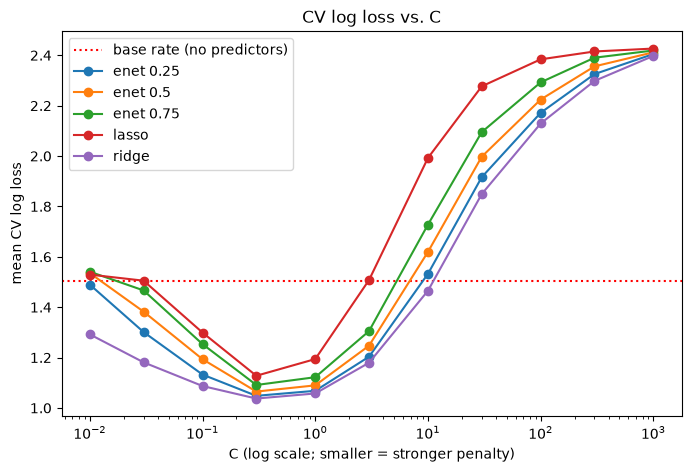

In [12]:
fig, ax = plt.subplots(figsize=(8, 5))
for name, g in all_results.groupby("model"):
    ax.errorbar(g["C"], g["log loss (mean)"], marker="o", capsize=3, label=name)
ax.axhline(ll_base, color="red", ls=":", label="base rate (no predictors)")
ax.set(xscale="log", xlabel="C (log scale; smaller = stronger penalty)",
       ylabel="mean CV log loss", title="CV log loss vs. C")
ax.legend()
plt.show()

- C = 0.3 gives the lowest CV log loss for all the models, with ridge the single lowest at 1.0374, and with the one-standard-error rule enet 0.75 is selected as the model with the least nonzero coefficients as it only keeps 27 out of the 54 total coefficients

##### Part b

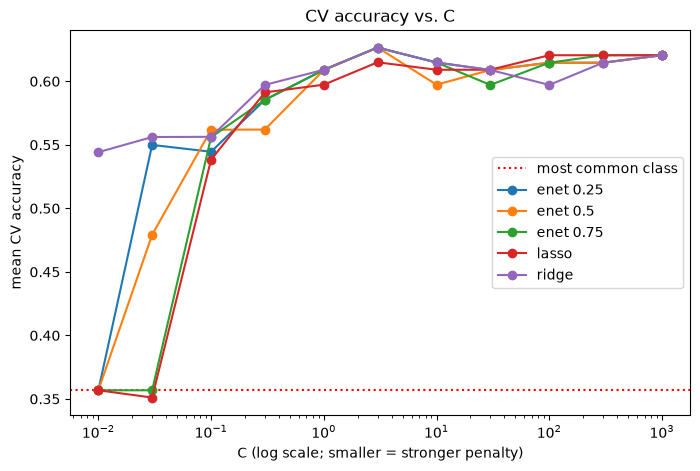

In [13]:
fig, ax = plt.subplots(figsize=(8, 5))
for name, g in all_results.groupby("model"):
    ax.errorbar(g["C"], g["accuracy (mean)"], marker="o", capsize=3, label=name)
ax.axhline((y_train == y_train.mode()[0]).mean(), color="red", ls=":", label="most common class")
ax.set(xscale="log", xlabel="C (log scale; smaller = stronger penalty)",
       ylabel="mean CV accuracy", title="CV accuracy vs. C")
ax.legend()
plt.show()

- C = 3 has the highest accuracy, but it only drops slightly as C increases further. The log loss gets significantly worse as C increases. Compared to the model in part a at C = 0.3 this model has a slightly higher accuracy but that is at the cost of also having a slightly higher log loss. This is similar to what we saw in the previous question with the nonpenalized model that had a high accuracy but also a very high log loss since the elemental predictors were linearly dependent on each other and as C is increased the models become closer to the unpenalized model


##### Part c

- The higher the C value is the lower the penalty being applied which means the linear dependency of the elemental predictors causes the wrong predictions to be even more wrong. Accuracy is not negatively impacted by the lack of a penalty on the elemental predictors with high collinearity which is why it only slightly decreased as C increases above 10. The accuracy is higher than the baseline since it is only measuring the class with the highest predicted value so the other classes' predictions do not matter.


##### Part d

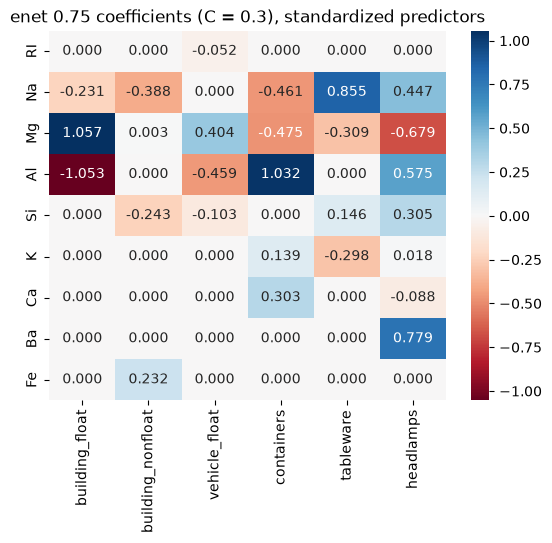

RI    1
Na    5
Mg    6
Al    4
Si    4
K     3
Ca    2
Ba    1
Fe    1
dtype: int64

In [14]:
model_best.fit(X_train, y_train)
coef_table = pd.DataFrame(
    model_best.named_steps["model"].coef_.T,
    index=features,
    columns=[class_names[c] for c in model_best.named_steps["model"].classes_],
)

sns.heatmap(coef_table, annot=True, fmt=".3f", cmap="RdBu", center=0)
plt.title(f"{method_best} coefficients (C = {C_best}), standardized predictors")
plt.show()

(coef_table != 0).sum(axis=1)

- RI, Ba and Fe all only have a nonzero coefficient for one class each


##### Part e

In [15]:
odds_Ba = np.exp(coef_table.loc["Ba", "headlamps"] - coef_table.loc["Ba", "building_float"])
odds_Mg = np.exp(coef_table.loc["Mg", "building_float"] - coef_table.loc["Mg", "headlamps"])
print(f"Ba, headlamps vs building_float: {odds_Ba:.3f}")
print(f"Mg, building_float vs headlamps: {odds_Mg:.3f}")

Ba, headlamps vs building_float: 2.180
Mg, building_float vs headlamps: 5.672


### Question 4

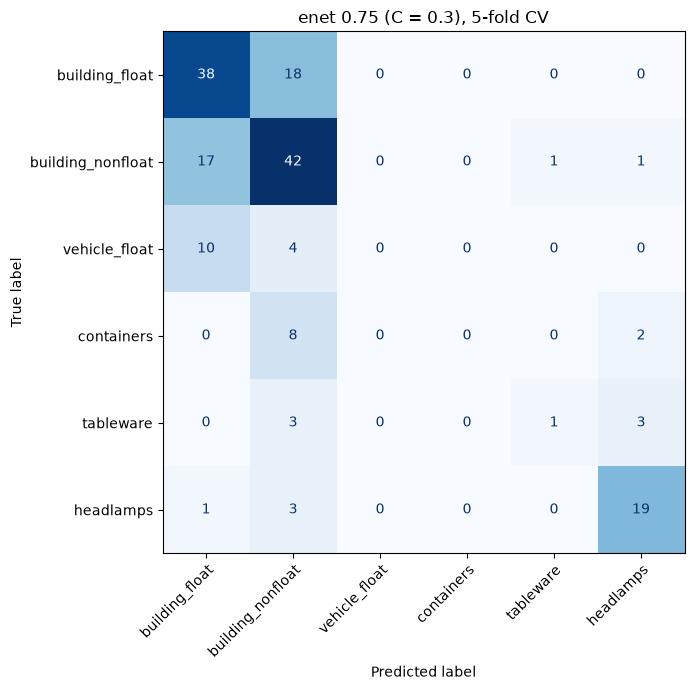

,precision,recall
building_float,0.576,0.679
building_nonfloat,0.538,0.689
vehicle_float,0.000,0.000
containers,0.000,0.000
tableware,0.500,0.143
headlamps,0.760,0.826


In [16]:
pred_best = cv_pred(model_best)

fig, ax = plt.subplots(figsize=(9.5, 7))
ConfusionMatrixDisplay.from_predictions(
    y_train, pred_best,
    display_labels=[class_names[c] for c in sorted(y_train.unique())],
    cmap="Blues", colorbar=False, ax=ax,
)
ax.set_title(f"{method_best} (C = {C_best}), 5-fold CV")
plt.setp(ax.get_xticklabels(), rotation=45, ha="right", rotation_mode="anchor")
plt.tight_layout()
plt.show()

precision_recall = pd.DataFrame({
    "precision": precision_score(y_train, pred_best, average=None),
    "recall": recall_score(y_train, pred_best, average=None),
}, index=[class_names[c] for c in sorted(y_train.unique())])
precision_recall.round(3)


##### Part a

- Vehicle_float and containers are never predicted at all, so they are never predicted correctly. Tableware is only predicted correctly 1 out of 7 times.


##### Part b

- Vehicle_float is most commonly predicted as building_float, and they may be hard to predict from each other since both are float-processed window glass, meaning they both go through the same process. The only thing that distinguishes them is what they are installed in, which none of the predictors give much insight into.


# Part 3: KNN + Model Comparisons

### Question 1

In [17]:
def make_knn(k, p):
    return Pipeline(steps=[
        ("scale", StandardScaler()),
        ("model", KNeighborsClassifier(n_neighbors=k, p=p)),
    ])

k_values = range(1, 32, 2)
knn_results = pd.DataFrame([{"k": k, "p": p, **cv_scores(make_knn(k, p))}
                            for p in (1, 2) for k in k_values])
knn_results.round(4)

,k,p,log loss (mean),log loss (sd),accuracy (mean),accuracy (sd)
0,1,1,10.3285,1.9404,0.7134,0.0538
1,3,1,4.1196,1.0725,0.7077,0.0826
2,5,1,2.8152,1.4837,0.6785,0.0713
3,7,1,1.8416,1.1790,0.6608,0.0543
4,9,1,1.4928,0.7274,0.6960,0.0629
5,11,1,1.5303,0.7222,0.6960,0.0682
6,13,1,1.5517,0.7257,0.7077,0.0517
7,15,1,1.3967,0.4744,0.6901,0.0437
8,17,1,1.4366,0.4685,0.6960,0.0601
9,19,1,1.4682,0.4771,0.6607,0.0583


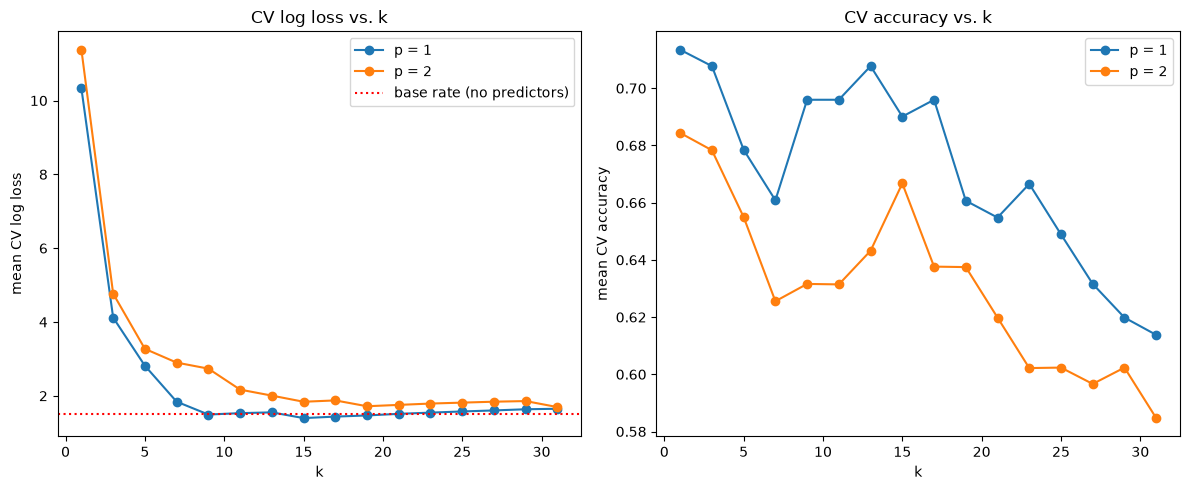

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for p, g in knn_results.groupby("p"):
    axes[0].plot(g["k"], g["log loss (mean)"], marker="o", label=f"p = {p}")
    axes[1].plot(g["k"], g["accuracy (mean)"], marker="o", label=f"p = {p}")
axes[0].axhline(ll_base, color="red", ls=":", label="base rate (no predictors)")
axes[0].set(xlabel="k", ylabel="mean CV log loss", title="CV log loss vs. k")
axes[1].set(xlabel="k", ylabel="mean CV accuracy", title="CV accuracy vs. k")
for ax in axes:
    ax.legend()
plt.tight_layout()
plt.show()

In [19]:
best_knn = knn_results.loc[knn_results["log loss (mean)"].idxmin()]
k_best, p_best = int(best_knn["k"]), int(best_knn["p"])
print(f"Lowest mean CV log loss: k = {k_best}, p = {p_best} ({best_knn['log loss (mean)']:.4f})")
model_knn = make_knn(k_best, p_best)

Lowest mean CV log loss: k = 15, p = 1 (1.3967)


##### Part a

- The lowest CV log loss is 1.3967, at k = 15 and p = 1


##### Part b

- The highest accuracy would be k = 1 and p = 1. This has the highest accuracy since it is always just selecting the closest neighbor but has the highest log loss since it is only using 1 sample to predict the value so therefore when it is wrong it is very wrong. This makes it a poor choice since it will always choose one class at 100% while a higher k uses a higher distribution giving a more realistic probability for each of the classes.


### Question 2

In [20]:
proba_knn = cross_val_predict(model_knn, X_train, y_train, cv=cv, method="predict_proba")
classes = np.sort(y_train.unique())
p_true = proba_knn[np.arange(len(y_train)), np.searchsorted(classes, y_train)]

eps = np.finfo(float).eps
zero_true = p_true == 0
row_loss = -np.log(np.clip(p_true, eps, 1 - eps))

print(f"fragments with probability exactly 0 for their true class: {zero_true.sum()}")
print(y_train[zero_true].map(class_names).value_counts().to_string())
print(f"\nlog loss added by one such fragment: {-np.log(eps):.4f}")
print(f"total KNN log loss (mean): {row_loss.mean():.4f}")
print(f"share of the total coming from those fragments: {row_loss[zero_true].sum() / row_loss.sum():.1%}")
print(f"mean log loss of the remaining fragments: {row_loss[~zero_true].mean():.4f}")

fragments with probability exactly 0 for their true class: 3
type
headlamps     2
containers    1

log loss added by one such fragment: 36.0437
total KNN log loss (mean): 1.3991
share of the total coming from those fragments: 45.2%
mean log loss of the remaining fragments: 0.7804


##### Part a

- There are 3 total fragments with a probability of 0 for their true class. Two are from headlamps and one is from containers.


##### Part b

- About 36 is added to the log loss for each of these fragments, and the three together make up about 45% of the total log loss. Just looking at the remaining fragments, the log loss goes from about 1.4 to 0.78.


### Question 3

In [21]:
pred_knn = cv_pred(model_knn)

comparison = pd.DataFrame({
    f"{method_best} (C = {C_best})": cv_scores(model_best),
    f"KNN (k = {k_best}, p = {p_best})": cv_scores(model_knn),
}).T
comparison.round(4)

,log loss (mean),log loss (sd),accuracy (mean),accuracy (sd)
enet 0.75 (C = 0.3),1.0912,0.1711,0.5854,0.0575
"KNN (k = 15, p = 1)",1.3967,0.4744,0.6901,0.0437


In [22]:
recall_table = pd.DataFrame({
    f"{method_best} (C = {C_best})": recall_score(y_train, pred_best, average=None),
    f"KNN (k = {k_best}, p = {p_best})": recall_score(y_train, pred_knn, average=None),
}, index=[class_names[c] for c in classes])
recall_table.round(3)

,enet 0.75 (C = 0.3),"KNN (k = 15, p = 1)"
building_float,0.679,0.964
building_nonfloat,0.689,0.721
vehicle_float,0.000,0.000
containers,0.000,0.200
tableware,0.143,0.000
headlamps,0.826,0.783


##### Part a

- Enet 0.75 with C = 0.3 has a lower log loss at about 1.1 vs 1.4, but KNN with k = 15 and p = 1 has a higher accuracy at about 69% vs 59%.


##### Part b

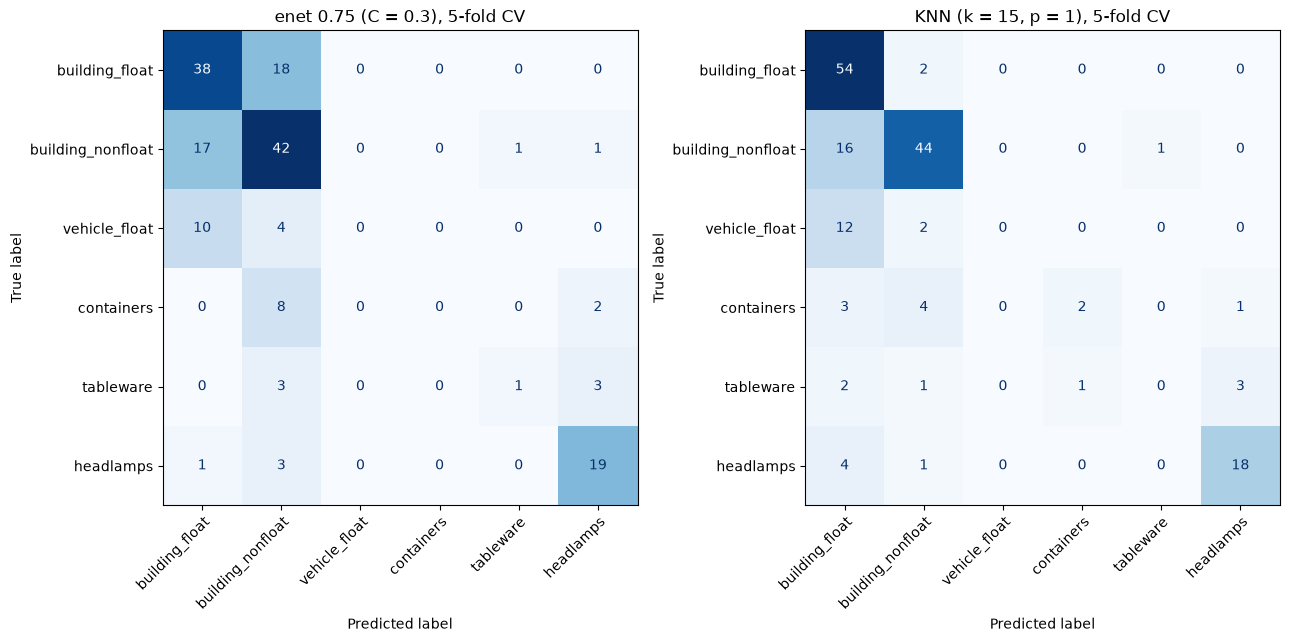

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(13, 6.5))
class_labels = [class_names[c] for c in sorted(y_train.unique())]
for ax, (name, pred) in zip(axes, [(f"{method_best} (C = {C_best})", pred_best),
                                   (f"KNN (k = {k_best}, p = {p_best})", pred_knn)]):
    ConfusionMatrixDisplay.from_predictions(
        y_train, pred, display_labels=class_labels, ax=ax, cmap="Blues", colorbar=False,
    )
    ax.set_title(f"{name}, 5-fold CV")
    plt.setp(ax.get_xticklabels(), rotation=45, ha="right", rotation_mode="anchor")
plt.tight_layout()
plt.show()


- KNN accuracy increase comes almost entirely from predicting building_float more accurately while the enet 0.75 model more regularly predicts building_float as building_nonfloat. This is not a good reason to prefer KNN because it causes KNN to predict 0 for the true class more often which significantly increases the log loss.


##### Part c

- KNN is better at handling building_float, building_nonfloat and containers, while worse at tableware and headlamps. This suggests the class boundaries for building_float, building_nonfloat and containers are all not straight, so the extra flexibility of KNN shapes is able to handle them better.


### Question 4

In [24]:
model_best.fit(X_train, y_train)
model_knn.fit(X_train, y_train)

test_results = pd.DataFrame({
    f"{method_best} (C = {C_best})": {
        "test log loss": log_loss(y_test, model_best.predict_proba(X_test)),
        "test accuracy": accuracy_score(y_test, model_best.predict(X_test)),
    },
    f"KNN (k = {k_best}, p = {p_best})": {
        "test log loss": log_loss(y_test, model_knn.predict_proba(X_test)),
        "test accuracy": accuracy_score(y_test, model_knn.predict(X_test)),
    },
}).T
test_results.round(4)

,test log loss,test accuracy
enet 0.75 (C = 0.3),0.8864,0.6512
"KNN (k = 15, p = 1)",0.7538,0.6279


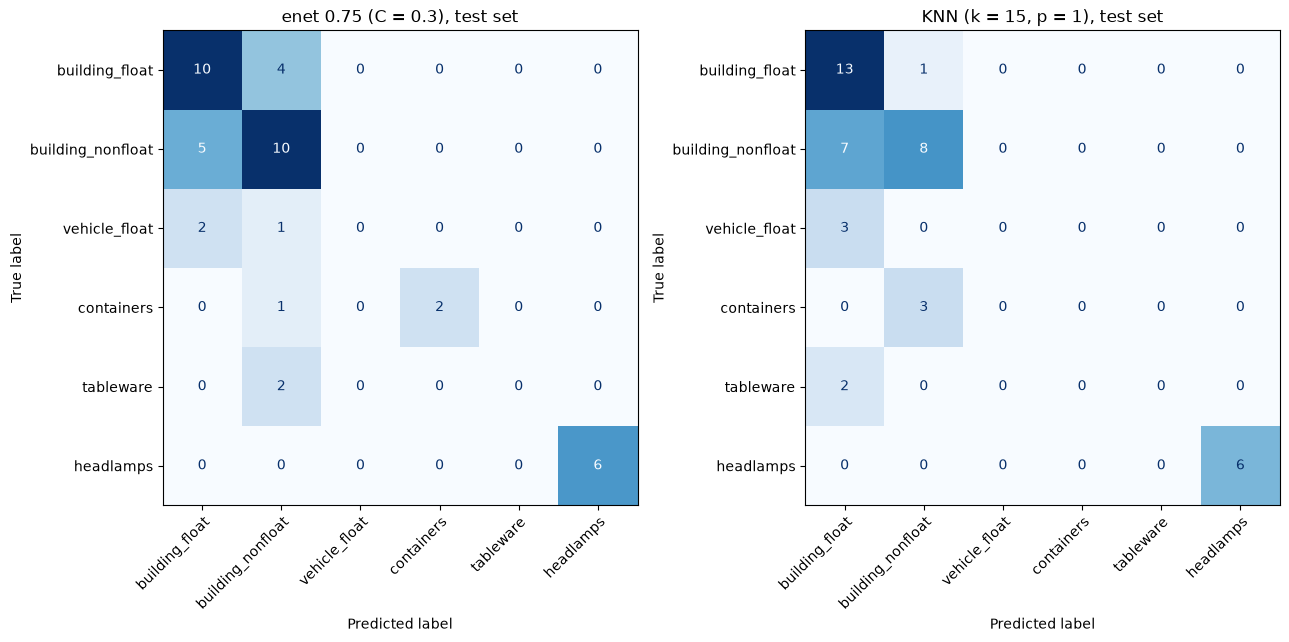

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(13, 6.5))
class_labels = [class_names[c] for c in sorted(y_train.unique())]
for ax, (name, m) in zip(axes, [(f"{method_best} (C = {C_best})", model_best),
                                (f"KNN (k = {k_best}, p = {p_best})", model_knn)]):
    ConfusionMatrixDisplay.from_predictions(
        y_test, m.predict(X_test), display_labels=class_labels, ax=ax, cmap="Blues", colorbar=False,
    )
    ax.set_title(f"{name}, test set")
    plt.setp(ax.get_xticklabels(), rotation=45, ha="right", rotation_mode="anchor")
plt.tight_layout()
plt.show()


##### Part a

- No, the log loss for KNN is now lower, but the accuracy for enet 0.75 is now higher, so both flip.


##### Part b

In [26]:
print(f"one fragment with probability 0 adds {-np.log(np.finfo(float).eps):.4f} to the summed test log loss")
print(f"over {len(y_test)} fragments that is a mean of {-np.log(np.finfo(float).eps) / len(y_test):.4f}")

one fragment with probability 0 adds 36.0437 to the summed test log loss
over 43 fragments that is a mean of 0.8382


- Since there are so few fragments for some of the classes in the test set, it is difficult to conclude anything about the per class performance from them, but you still can make conclusions on the larger classes like building_float and building_nonfloat. A single wrong fragment with a predicted probability of 0 still adds 36 when summed, and about 0.84 to the mean over 43 fragments. That is larger than KNN's entire test log loss, so one such fragment would drastically change the picture between the two models.


### AI Acknowledgment
I used an AI assistant to help write code for this lab. I checked the outputs myself against the data and the class materials to make sure the code worked correctly. I also used AI to help with spelling and grammar in my written answers. All questions were answered in my own words.